<a href="https://colab.research.google.com/github/xccurit/project_uts_deeplearning/blob/main/PROJECT_UTS_DEEP_LEARNING_MLP_REGRESI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- Memproses file: Tabel Harga Berdasarkan Komoditas - Beras Kualitas Medium I.xlsx ---
Header Provinsi terdeteksi: 'Semua Provinsi'
Berhasil mengekstrak 7298 titik data harga yang valid.

--- Memproses file: Tabel Harga Berdasarkan Komoditas - Cabai Merah Besar.xlsx ---
Header Provinsi terdeteksi: 'Semua Provinsi'
Berhasil mengekstrak 5825 titik data harga yang valid.

🚀 Menggunakan perangkat komputasi: cpu


MENGOLAH DATA & TRAINING MODEL: BERAS KUALITAS MEDIUM I


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Epoch 10/50 | Train Loss: 0.0022 | Val Loss: 0.0019
Epoch 20/50 | Train Loss: 0.0005 | Val Loss: 0.0007
Epoch 30/50 | Train Loss: 0.0004 | Val Loss: 0.0007
Epoch 40/50 | Train Loss: 0.0004 | Val Loss: 0.0007
Epoch 50/50 | Train Loss: 0.0004 | Val Loss: 0.0007

✅ Bobot model berhasil disimpan: baseline_mlp_Beras_Kualitas_Medium_I.pth

=== METRIK EVALUASI: BERAS KUALITAS MEDIUM I ===
MSE  : 428.13
RMSE : 20.69
MAE  : 18.35


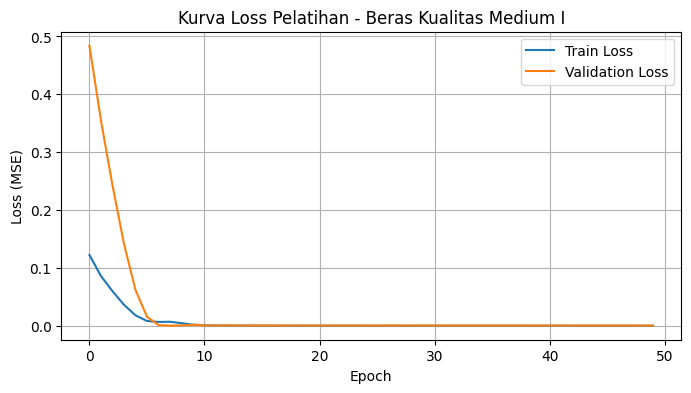

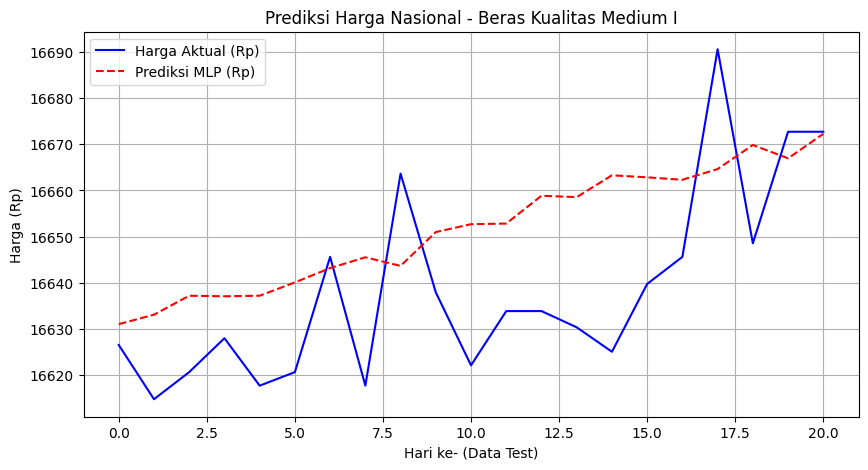


MENGOLAH DATA & TRAINING MODEL: CABAI MERAH BESAR


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Epoch 10/50 | Train Loss: 0.0120 | Val Loss: 0.0073
Epoch 20/50 | Train Loss: 0.0055 | Val Loss: 0.0019
Epoch 30/50 | Train Loss: 0.0035 | Val Loss: 0.0009
Epoch 40/50 | Train Loss: 0.0028 | Val Loss: 0.0008
Epoch 50/50 | Train Loss: 0.0022 | Val Loss: 0.0007

✅ Bobot model berhasil disimpan: baseline_mlp_Cabai_Merah_Besar.pth

=== METRIK EVALUASI: CABAI MERAH BESAR ===
MSE  : 5662032.68
RMSE : 2379.50
MAE  : 2034.20


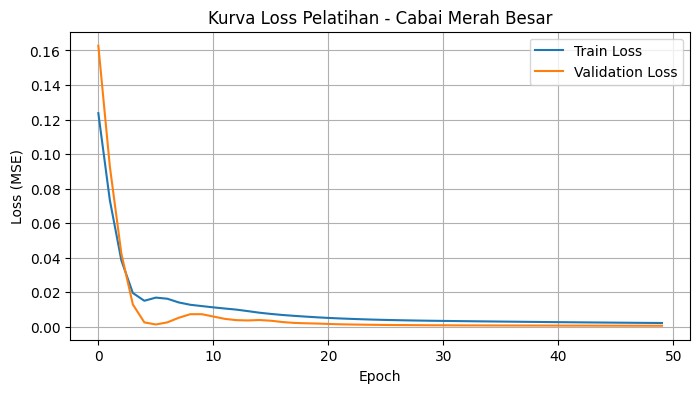

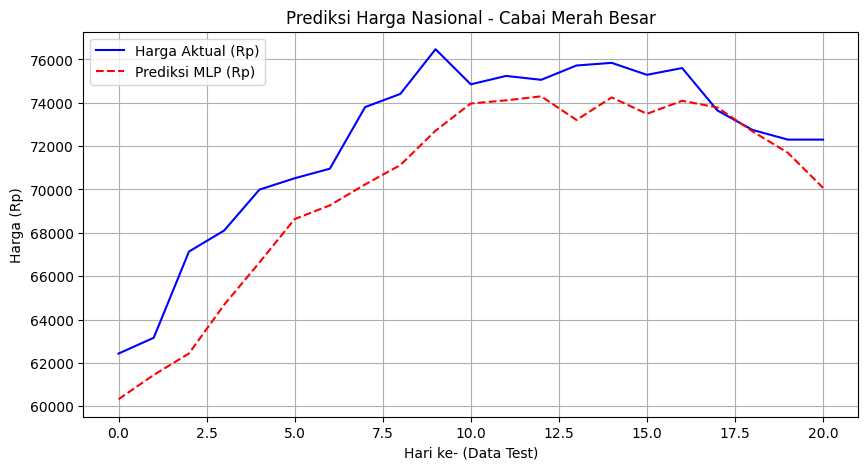

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ==========================================
# 0. MOUNT GOOGLE DRIVE
# ==========================================
from google.colab import drive
drive.mount('/content/drive')

# ==========================================
# 1. LOAD & PREPROCESSING DATA DARI PIHPS
# ==========================================
def proses_data_pihps(file_path):
    print(f"\n--- Memproses file: {file_path.split('/')[-1]} ---")
    df_raw = pd.read_excel(file_path, header=None)

    # 1. Deteksi Baris Header Secara Otomatis
    header_idx = 0
    for i in range(min(20, len(df_raw))):
        row_str = ' '.join(df_raw.iloc[i].astype(str).str.lower().tolist())
        if 'provinsi' in row_str or 'daerah' in row_str or 'pasar' in row_str:
            header_idx = i
            break

    df = pd.read_excel(file_path, skiprows=header_idx)

    # 2. Hapus kolom nomor jika ada di awal
    if 'no' in str(df.columns[0]).lower() or df.columns[0] == 'I':
        df = df.drop(columns=[df.columns[0]])

    prov_col = df.columns[0]
    print(f"Header Provinsi terdeteksi: '{prov_col}'")

    # 3. Simpan urutan tanggal asli
    kolom_tanggal = list(df.columns[1:])

    # 4. Buang baris kosong atau baris rekap
    df = df.dropna(subset=[prov_col])
    df = df[~df[prov_col].astype(str).str.contains('Rata-rata|Nasional|Total', case=False, na=False)]

    # 5. Transformasi ke bentuk Time-Series (Melt)
    df_melted = df.melt(id_vars=[prov_col], value_vars=kolom_tanggal, var_name='Tanggal', value_name='Harga')
    df_melted['Tanggal'] = pd.Categorical(df_melted['Tanggal'], categories=kolom_tanggal, ordered=True)

    # 6. Fungsi Pembersih Angka
    def bersihkan_harga(x):
        if pd.isna(x): return np.nan
        x_str = str(x).strip()
        if x_str in ['-', '']: return np.nan
        x_str = x_str.replace('.', '').replace(',', '')
        try: return float(x_str)
        except: return np.nan

    df_melted['Harga'] = df_melted['Harga'].apply(bersihkan_harga)

    valid_count = df_melted['Harga'].notna().sum()
    print(f"Berhasil mengekstrak {valid_count} titik data harga yang valid.")

    return df_melted

# Path file di Google Drive (Gunakan _2.xlsx sesuai konfirmasi terakhir)
path_beras = '/content/drive/MyDrive/Tabel Harga Berdasarkan Komoditas - Beras Kualitas Medium I.xlsx'
path_cabai = '/content/drive/MyDrive/Tabel Harga Berdasarkan Komoditas - Cabai Merah Besar.xlsx'

df_beras = proses_data_pihps(path_beras)
df_cabai = proses_data_pihps(path_cabai)

# 7. Hitung rata-rata nasional harian
nasional_beras = df_beras.groupby('Tanggal', observed=False)['Harga'].mean().reset_index()
nasional_cabai = df_cabai.groupby('Tanggal', observed=False)['Harga'].mean().reset_index()

# 8. Tambal Data Hari Libur
nasional_beras['Harga'] = nasional_beras['Harga'].ffill().bfill()
nasional_beras = nasional_beras.dropna(subset=['Harga'])

nasional_cabai['Harga'] = nasional_cabai['Harga'].ffill().bfill()
nasional_cabai = nasional_cabai.dropna(subset=['Harga'])

if len(nasional_cabai) == 0 or len(nasional_beras) == 0:
    raise ValueError("ERROR FATAL: Data kosong! Pastikan file Excel tidak rusak.")

# ==========================================
# 2. DEFINISI MODEL & FUNGSI TRAINING
# ==========================================
WINDOW_SIZE = 14
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n======================================")
print(f"🚀 Menggunakan perangkat komputasi: {device}")
print(f"======================================\n")

class MLPRegressor(nn.Module):
    def __init__(self, input_size):
        super(MLPRegressor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

def create_sequences(data, window_size=14):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size, 0])
        y.append(data[i+window_size, 0])
    return np.array(X), np.array(y)

def latih_dan_evaluasi_model(nama_komoditas, df_data):
    print(f"\n=======================================================")
    print(f"MENGOLAH DATA & TRAINING MODEL: {nama_komoditas.upper()}")
    print(f"=======================================================")

    data_harga = df_data['Harga'].values.reshape(-1, 1)

    scaler = MinMaxScaler()
    data_scaled = scaler.fit_transform(data_harga)

    X, y = create_sequences(data_scaled, WINDOW_SIZE)

    train_size = int(len(X) * 0.8)
    val_size = int(len(X) * 0.1)

    X_train, y_train = X[:train_size], y[:train_size]
    X_val, y_val = X[train_size:train_size+val_size], y[train_size:train_size+val_size]
    X_test, y_test = X[train_size+val_size:], y[train_size+val_size:]

    train_loader = DataLoader(TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)), batch_size=32, shuffle=False)
    val_loader = DataLoader(TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32)), batch_size=32, shuffle=False)

    model = MLPRegressor(WINDOW_SIZE).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()

    train_losses, val_losses = [], []
    EPOCHS = 50

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs).squeeze()
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)

        val_loss = 0.0
        model.eval()
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs).squeeze()
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)

        train_losses.append(running_loss / len(train_loader.dataset))
        val_losses.append(val_loss / len(val_loader.dataset))

        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1:02d}/{EPOCHS} | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f}")

    # ==========================================
    # -> KODE UNTUK MENYIMPAN FILE .pth
    # ==========================================
    nama_file_pth = f"baseline_mlp_{nama_komoditas.replace(' ', '_')}.pth"
    torch.save(model.state_dict(), nama_file_pth)
    print(f"\n✅ Bobot model berhasil disimpan: {nama_file_pth}")

    # ==========================================
    # Evaluasi Data Test
    # ==========================================
    model.eval()
    with torch.no_grad():
        X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
        preds_scaled = model(X_test_tensor).cpu().numpy()

    preds = scaler.inverse_transform(preds_scaled.reshape(-1, 1))
    actual = scaler.inverse_transform(y_test.reshape(-1, 1))

    mse = mean_squared_error(actual, preds)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(actual, preds)

    print(f"\n=== METRIK EVALUASI: {nama_komoditas.upper()} ===")
    print(f"MSE  : {mse:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"MAE  : {mae:.2f}")

    # Visualisasi Kurva Loss
    plt.figure(figsize=(8, 4))
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.title(f'Kurva Loss Pelatihan - {nama_komoditas}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss (MSE)')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Visualisasi Prediksi vs Aktual
    plt.figure(figsize=(10, 5))
    plt.plot(actual, label=f'Harga Aktual (Rp)', color='blue')
    plt.plot(preds, label=f'Prediksi MLP (Rp)', color='red', linestyle='--')
    plt.title(f'Prediksi Harga Nasional - {nama_komoditas}')
    plt.xlabel('Hari ke- (Data Test)')
    plt.ylabel('Harga (Rp)')
    plt.legend()
    plt.grid(True)
    plt.show()

# ==========================================
# 3. JALANKAN UNTUK KEDUA KOMODITAS
# ==========================================
latih_dan_evaluasi_model("Beras Kualitas Medium I", nasional_beras)
latih_dan_evaluasi_model("Cabai Merah Besar", nasional_cabai)